# 01 — Explore the data

Phase 1 of the Karachi Air-Quality Forecaster: look at the raw data before we
clean or model anything. We check **how much data we have, how good it is,
what it looks like over time, and how the different sources relate to each
other** (spec §5, §6.4). Nothing here is cleaned or saved — Phase 2 does that,
using the rules we propose at the end.

Data used (all hourly, Asia/Karachi time):
- **D1** — 14 low-cost PM2.5 sensors (`data/raw/sensors/S1..S14.csv`)
- **D5** — US Consulate reference-grade monitor (`data/raw/us_consulate/8156.csv`)
- **D2** — Open-Meteo ERA5 weather per sensor site (`data/raw/weather/S*.csv`)
- **D3** — CAMS modelled air quality per sensor site (`data/raw/air_quality/S*.csv`)


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3


def find_root(start: Path) -> Path:
    '''Walk up from `start` until we find the folder that holds PROJECT_SPEC.md.'''
    for p in [start, *start.parents]:
        if (p / "PROJECT_SPEC.md").exists():
            return p
    raise FileNotFoundError("Could not find project root (no PROJECT_SPEC.md in any parent)")


ROOT = find_root(Path.cwd())
RAW = ROOT / "data" / "raw"
REPORT_PATH = ROOT / "docs" / "report" / "data_exploration.md"
TZ = "Asia/Karachi"

SENSOR_IDS = [f"S{i}" for i in range(1, 15)]
SENSOR_SORT = {sid: i for i, sid in enumerate(SENSOR_IDS)}


def sort_sensors(ids):
    return sorted(ids, key=lambda s: SENSOR_SORT.get(s, 999))


print(f"Project root : {ROOT}")
print(f"Raw data dir : {RAW}")


Project root : C:\Users\ADMIN\Documents\personal\University\CCP Projects\Karachi Air Quality Forecaster
Raw data dir : C:\Users\ADMIN\Documents\personal\University\CCP Projects\Karachi Air Quality Forecaster\data\raw


## 1. Load

Each source is one CSV per site. We load them all and stack them into one
tidy table per source, with a `sensor_id` column saying which site a row
belongs to — the standard "long" layout for time series from several sites.


In [2]:
def load_many(folder: Path, ids: list[str]) -> pd.DataFrame:
    '''Read one CSV per id from `folder`, tag each with its sensor_id, stack into one table.'''
    frames = []
    for sid in ids:
        df = pd.read_csv(folder / f"{sid}.csv", parse_dates=["time"])
        df.insert(0, "sensor_id", sid)
        frames.append(df)
    return pd.concat(frames, ignore_index=True)


sensors = load_many(RAW / "sensors", SENSOR_IDS)    # D1: low-cost PM2.5, hourly
weather = load_many(RAW / "weather", SENSOR_IDS)    # D2: ERA5 weather, hourly
cams = load_many(RAW / "air_quality", SENSOR_IDS)   # D3: CAMS modelled pollution, hourly

consulate = pd.read_csv(RAW / "us_consulate" / "8156.csv", parse_dates=["time"])
consulate.insert(0, "sensor_id", "US_CONSULATE")

for name, df in [("sensors", sensors), ("weather", weather), ("cams", cams), ("consulate", consulate)]:
    print(f"{name:10s} rows={len(df):>7,}  tz={df['time'].dt.tz}  span={df['time'].min()} -> {df['time'].max()}")


sensors    rows=102,110  tz=UTC+05:00  span=2025-06-19 12:00:00+05:00 -> 2026-11-08 18:00:00+05:00
weather    rows=186,816  tz=UTC+05:00  span=2025-05-01 00:00:00+05:00 -> 2026-11-07 23:00:00+05:00
cams       rows=186,816  tz=UTC+05:00  span=2025-05-01 00:00:00+05:00 -> 2026-11-07 23:00:00+05:00
consulate  rows= 46,937  tz=UTC+05:00  span=2019-05-23 02:00:00+05:00 -> 2025-03-04 16:00:00+05:00


## 2. Coverage per sensor

For each site: first/last reading, how many hours we *should* have between
those two dates versus how many we *actually* have, the percentage this
gives (% complete), how many full days have at least 18 of 24 hours (the
"complete day" rule from spec §5.3 — the same threshold EPA uses for a valid
daily average), and the single longest run of missing hours (the *longest
gap*).


In [3]:
def coverage_table(df: pd.DataFrame, value_col: str = "pm25", min_valid_hours: int = 18) -> pd.DataFrame:
    rows = []
    for sid, g in df.groupby("sensor_id"):
        g = g.dropna(subset=["time"]).drop_duplicates("time").sort_values("time")
        start, end = g["time"].min(), g["time"].max()
        full_idx = pd.date_range(start, end, freq="h", tz=g["time"].dt.tz)
        s = g.set_index("time")[value_col].reindex(full_idx)

        expected_hours = len(full_idx)
        present_hours = int(s.notna().sum())
        daily_valid = s.notna().groupby(s.index.date).sum()
        complete_days = int((daily_valid >= min_valid_hours).sum())
        total_days = int(daily_valid.shape[0])

        is_na = s.isna()
        gap_id = (~is_na).cumsum()
        gap_lengths = is_na.groupby(gap_id).sum()
        longest_gap = int(gap_lengths.max()) if len(gap_lengths) else 0

        rows.append(dict(
            sensor_id=sid, start=start, end=end,
            expected_hours=expected_hours, present_hours=present_hours,
            pct_complete=round(present_hours / expected_hours * 100, 1),
            complete_days=complete_days, total_days=total_days,
            longest_gap_hours=longest_gap,
        ))
    out = pd.DataFrame(rows)
    out["sensor_id"] = pd.Categorical(out["sensor_id"], categories=sort_sensors(out["sensor_id"]), ordered=True)
    return out.sort_values("sensor_id").reset_index(drop=True)


sensor_coverage = coverage_table(sensors)
consulate_coverage = coverage_table(consulate)
display(sensor_coverage)
display(consulate_coverage)

total_complete_sensor_days = int(sensor_coverage["complete_days"].sum())
print(f"\nTotal complete sensor-days across all 14 sensors: {total_complete_sensor_days:,}")
print(f"Mean % complete across sensors: {sensor_coverage['pct_complete'].mean():.1f}%")


,sensor_id,start,end,expected_hours,present_hours,pct_complete,complete_days,total_days,longest_gap_hours
0,S1,2025-07-02 16:00:00+05:00,2026-11-08 18:00:00+05:00,11859,10156,85.6,418,495,577
1,S2,2025-06-21 13:00:00+05:00,2026-10-27 14:00:00+05:00,11834,10020,84.7,415,494,1343
2,S3,2025-06-19 12:00:00+05:00,2026-11-08 18:00:00+05:00,12175,10346,85.0,414,508,433
3,S4,2025-06-23 13:00:00+05:00,2026-10-24 07:00:00+05:00,11707,9457,80.8,391,489,651
4,S5,2025-06-23 20:00:00+05:00,2026-11-08 18:00:00+05:00,12071,9406,77.9,387,504,1087
5,S6,2025-07-07 09:00:00+05:00,2026-11-06 11:00:00+05:00,11691,9148,78.2,368,488,724
6,S7,2025-06-23 15:00:00+05:00,2026-11-08 18:00:00+05:00,12076,7064,58.5,285,504,2351
7,S8,2025-06-23 22:00:00+05:00,2026-11-07 13:00:00+05:00,12040,6950,57.7,266,503,988
8,S9,2025-06-20 20:00:00+05:00,2026-11-07 17:00:00+05:00,12118,5973,49.3,241,506,2662
9,S10,2025-06-21 14:00:00+05:00,2026-03-19 13:00:00+05:00,6504,5557,85.4,228,272,290


,sensor_id,start,end,expected_hours,present_hours,pct_complete,complete_days,total_days,longest_gap_hours
0,US_CONSULATE,2019-05-23 02:00:00+05:00,2025-03-04 16:00:00+05:00,50703,36418,71.8,1454,2113,1635



Total complete sensor-days across all 14 sensors: 4,113
Mean % complete across sensors: 66.4%


A heat map makes the pattern easier to see than a table: one row per sensor,
one column per calendar week, coloured by what fraction of that week's hours
are present. Sensors are reindexed onto the *same* week grid (from the
earliest to the latest reading of any sensor), so a sensor that came online
later just shows as empty (0%) before it existed.


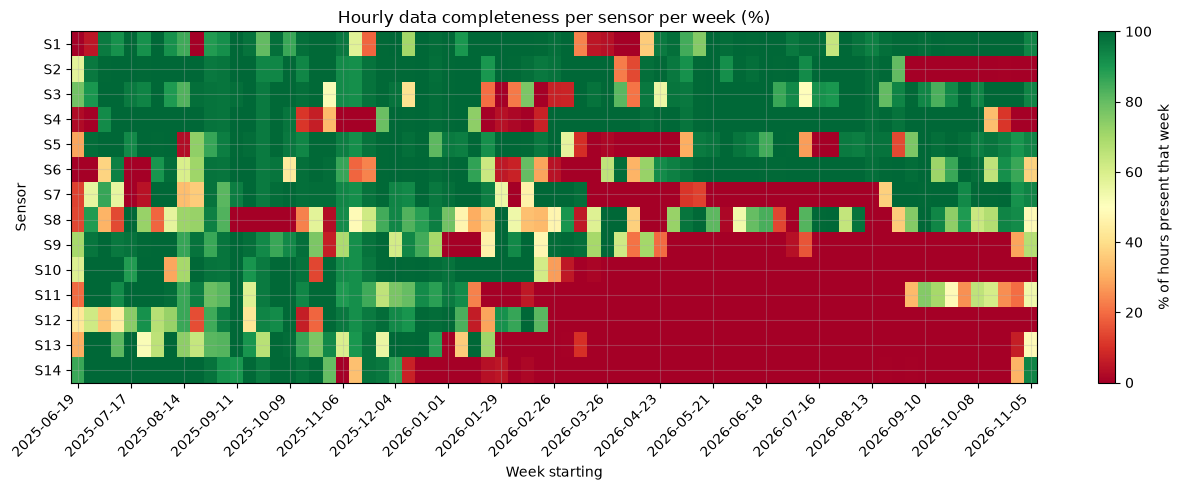

In [4]:
def weekly_completeness(df: pd.DataFrame, value_col: str = "pm25") -> pd.DataFrame:
    tz = df["time"].dt.tz
    global_start = df["time"].min().floor("D")
    global_end = df["time"].max().ceil("D")
    full_idx = pd.date_range(global_start, global_end, freq="h", tz=tz)

    present = {}
    for sid, g in df.groupby("sensor_id"):
        g = g.dropna(subset=["time"]).drop_duplicates("time").sort_values("time")
        s = g.set_index("time")[value_col].reindex(full_idx)
        present[sid] = s.notna().astype(float)

    present_df = pd.DataFrame(present)
    weekly = present_df.resample("7D").mean() * 100  # rows = week start, cols = sensor_id
    return weekly[sort_sensors(weekly.columns)].T


heat = weekly_completeness(sensors)

fig, ax = plt.subplots(figsize=(13, 5))
im = ax.imshow(heat.values, aspect="auto", cmap="RdYlGn", vmin=0, vmax=100)
ax.set_yticks(range(len(heat.index)))
ax.set_yticklabels(heat.index)
tick_pos = range(0, heat.shape[1], 4)
ax.set_xticks(list(tick_pos))
ax.set_xticklabels([heat.columns[i].strftime("%Y-%m-%d") for i in tick_pos], rotation=45, ha="right")
ax.set_xlabel("Week starting")
ax.set_ylabel("Sensor")
ax.set_title("Hourly data completeness per sensor per week (%)")
fig.colorbar(im, ax=ax, label="% of hours present that week")
plt.tight_layout()
plt.show()


## 3. Faults / quality

We only *measure* problems here — nothing gets cleaned or dropped. Per
sensor we count:
- **negatives** — physically impossible PM2.5 readings
- **zeros** — exact-zero readings (plausible but worth watching if frequent)
- **flat-line hours** — the same value repeated for ≥6 consecutive hours (a
  classic sign of a stuck sensor)
- **spikes** — readings above 500 µg/m³, or more than 5× the surrounding
  24-hour rolling median
- **observed < expected** — hours where OpenAQ's own hourly aggregate was
  built from fewer sub-hourly samples than expected (a weaker reading)


In [5]:
def fault_counts(df: pd.DataFrame, value_col: str = "pm25") -> pd.DataFrame:
    tz = df["time"].dt.tz
    rows = []
    for sid, g in df.groupby("sensor_id"):
        g = g.dropna(subset=["time"]).drop_duplicates("time").sort_values("time")
        full_idx = pd.date_range(g["time"].min(), g["time"].max(), freq="h", tz=tz)
        gi = g.set_index("time").reindex(full_idx)
        s = gi[value_col]
        is_valid = s.notna()

        negatives = int((s < 0).sum())
        zeros = int((s == 0).sum())

        same_as_prev = (s == s.shift(1)) & is_valid & is_valid.shift(1).fillna(False)
        run_id = (~same_as_prev).cumsum()
        run_len = is_valid.groupby(run_id).transform("size").where(is_valid)
        flat_hours = int((run_len >= 6).sum())

        roll_med = s.rolling(25, center=True, min_periods=6).median()
        is_spike = ((s > 500) | ((roll_med > 1) & (s > 5 * roll_med))) & is_valid
        spikes = int(is_spike.sum())

        under_reported = int((gi["observed_count"] < gi["expected_count"]).sum())

        rows.append(dict(
            sensor_id=sid, valid_hours=int(is_valid.sum()), negatives=negatives, zeros=zeros,
            flat_line_hours=flat_hours, spikes=spikes, observed_lt_expected=under_reported,
        ))
    out = pd.DataFrame(rows)
    out["sensor_id"] = pd.Categorical(out["sensor_id"], categories=sort_sensors(out["sensor_id"]), ordered=True)
    return out.sort_values("sensor_id").reset_index(drop=True)


sensor_faults = fault_counts(sensors)
consulate_faults = fault_counts(consulate)
display(sensor_faults)
display(consulate_faults)

fault_totals = sensor_faults[["negatives", "zeros", "flat_line_hours", "spikes", "observed_lt_expected"]].sum()
print("\nTotals across all 14 sensors:")
print(fault_totals.to_string())


,sensor_id,valid_hours,negatives,zeros,flat_line_hours,spikes,observed_lt_expected
0,S1,10156,0,0,0,2,0
1,S2,10020,0,5,0,20,0
2,S3,10346,0,0,0,1,0
3,S4,9457,0,0,0,1,0
4,S5,9406,0,0,0,9,0
5,S6,9148,0,0,0,4,0
6,S7,7064,0,0,0,0,0
7,S8,6950,0,0,0,0,0
8,S9,5973,0,0,0,11,0
9,S10,5557,0,0,0,24,0


,sensor_id,valid_hours,negatives,zeros,flat_line_hours,spikes,observed_lt_expected
0,US_CONSULATE,36418,0,32,12,24,0



Totals across all 14 sensors:
negatives                0
zeros                    5
flat_line_hours          0
spikes                  79
observed_lt_expected     0


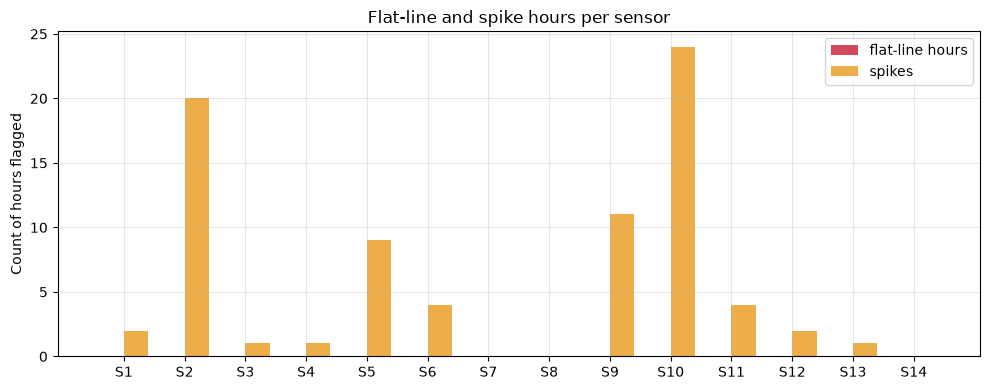

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(sensor_faults))
ax.bar(x - 0.2, sensor_faults["flat_line_hours"], width=0.4, label="flat-line hours", color="#d1495b")
ax.bar(x + 0.2, sensor_faults["spikes"], width=0.4, label="spikes", color="#edae49")
ax.set_xticks(x)
ax.set_xticklabels(sensor_faults["sensor_id"])
ax.set_ylabel("Count of hours flagged")
ax.set_title("Flat-line and spike hours per sensor")
ax.legend()
plt.tight_layout()
plt.show()


**Proposed Phase 2 fault rules** (to apply when cleaning, not here):
- Drop (set to missing) any negative reading — physically impossible.
- Drop spikes as defined above (>500 µg/m³ or >5× the 25-hour rolling
  median) before imputing, then treat the hour as missing for interpolation.
- Flag flat-line runs ≥6 hours as suspect; if a run is ≥24 hours treat the
  whole run as missing (a stuck sensor, not real stagnant air — persistent
  smog still drifts slightly hour to hour).
- Keep zeros (plausible after rain) unless they are also part of a flagged
  flat-line run.
- `observed_count < expected_count` hours are kept but down-weighted / noted,
  since they are a real (if partial) hourly average, not a fault.
- Any day with <18 valid hours after the above does not count towards a
  "complete day" and its target/lag features are left as missing rather than
  filled.


## 4. Distribution & seasonality

Daily means (requiring ≥18 valid hours, same rule as above) for all 14
sensors, the Consulate on its own timeline, a monthly box plot pooling every
sensor-day by calendar month, the diurnal (hour-of-day) cycle, and the
weekday pattern.


In [7]:
def daily_mean(df: pd.DataFrame, value_col: str = "pm25", min_valid_hours: int = 18) -> pd.DataFrame:
    out = {}
    for sid, g in df.groupby("sensor_id"):
        g = g.dropna(subset=["time", value_col]).drop_duplicates("time").sort_values("time")
        s = g.set_index("time")[value_col]
        m = s.resample("D").mean()
        n = s.resample("D").count()
        out[sid] = m.where(n >= min_valid_hours)
    return pd.DataFrame(out)


sensor_daily = daily_mean(sensors)
consulate_daily = daily_mean(consulate)["US_CONSULATE"]
sensor_city_avg_daily = sensor_daily.mean(axis=1)  # simple average across whichever sensors have a value that day


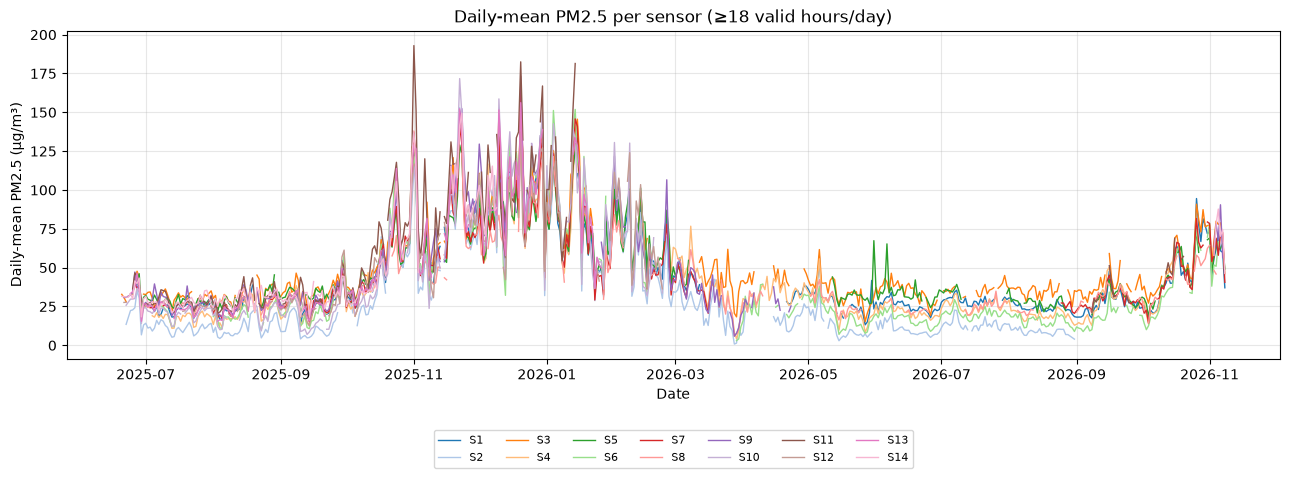

In [8]:
fig, ax = plt.subplots(figsize=(13, 5))
cmap = plt.get_cmap("tab20")
for i, sid in enumerate(sort_sensors(sensor_daily.columns)):
    ax.plot(sensor_daily.index, sensor_daily[sid], label=sid, color=cmap(i % 20), linewidth=1)
ax.set_xlabel("Date")
ax.set_ylabel("Daily-mean PM2.5 (µg/m³)")
ax.set_title("Daily-mean PM2.5 per sensor (≥18 valid hours/day)")
ax.legend(ncol=7, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.2))
plt.tight_layout()
plt.show()


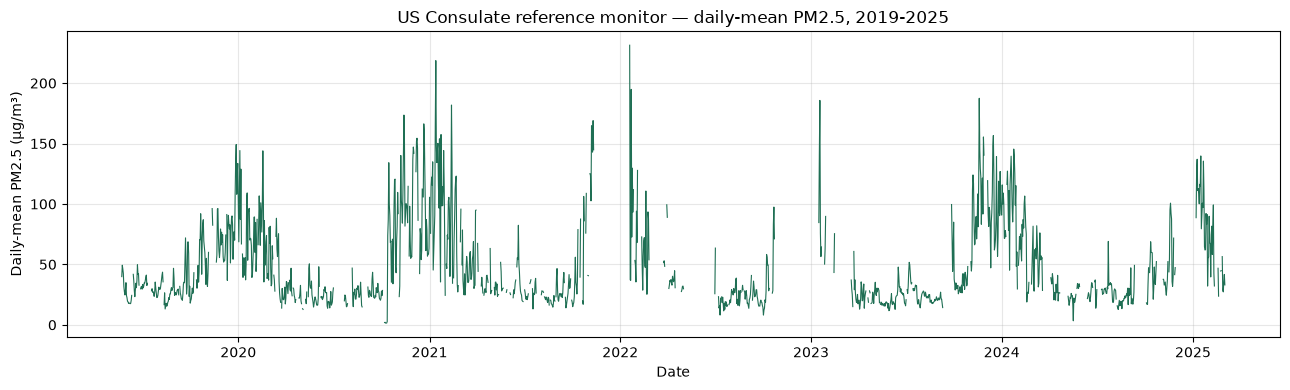

In [9]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(consulate_daily.index, consulate_daily.values, color="#1f6f54", linewidth=0.8)
ax.set_xlabel("Date")
ax.set_ylabel("Daily-mean PM2.5 (µg/m³)")
ax.set_title("US Consulate reference monitor — daily-mean PM2.5, 2019-2025")
plt.tight_layout()
plt.show()


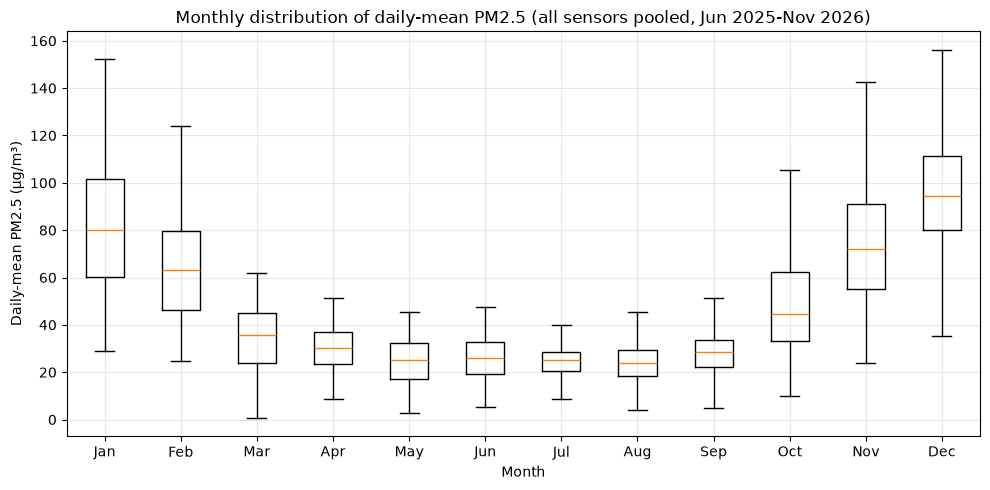

In [10]:
pooled = sensor_daily.stack().rename("pm25").reset_index()
pooled.columns = ["date", "sensor_id", "pm25"]
pooled["month"] = pooled["date"].dt.month

data_by_month = [pooled.loc[pooled["month"] == m, "pm25"].dropna().values for m in range(1, 13)]
month_labels = [pd.Timestamp(2024, m, 1).strftime("%b") for m in range(1, 13)]

fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot(data_by_month, tick_labels=month_labels, showfliers=False)
ax.set_xlabel("Month")
ax.set_ylabel("Daily-mean PM2.5 (µg/m³)")
ax.set_title("Monthly distribution of daily-mean PM2.5 (all sensors pooled, Jun 2025-Nov 2026)")
plt.tight_layout()
plt.show()


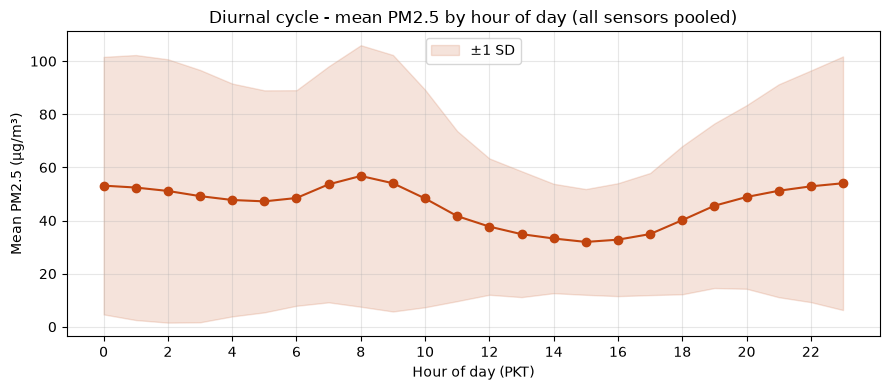

In [11]:
hourly = sensors.dropna(subset=["pm25"]).copy()
hourly["hour"] = hourly["time"].dt.hour
diurnal = hourly.groupby("hour")["pm25"].agg(["mean", "std"])

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(diurnal.index, diurnal["mean"], color="#c1440e", marker="o")
ax.fill_between(diurnal.index, diurnal["mean"] - diurnal["std"], diurnal["mean"] + diurnal["std"],
                 color="#c1440e", alpha=0.15, label="±1 SD")
ax.set_xlabel("Hour of day (PKT)")
ax.set_ylabel("Mean PM2.5 (µg/m³)")
ax.set_title("Diurnal cycle - mean PM2.5 by hour of day (all sensors pooled)")
ax.set_xticks(range(0, 24, 2))
ax.legend()
plt.tight_layout()
plt.show()


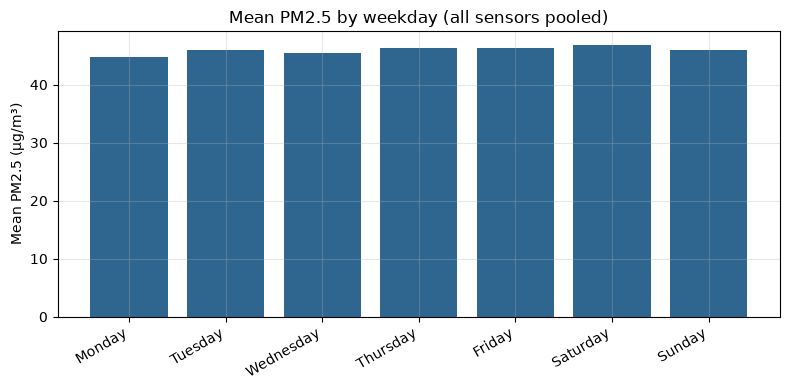

In [12]:
hourly["weekday"] = hourly["time"].dt.day_name()
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_mean = hourly.groupby("weekday")["pm25"].mean().reindex(weekday_order)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(weekday_mean.index, weekday_mean.values, color="#2f6690")
ax.set_ylabel("Mean PM2.5 (µg/m³)")
ax.set_title("Mean PM2.5 by weekday (all sensors pooled)")
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
plt.tight_layout()
plt.show()


## 5. Bands

Daily means (≥18 valid hours) classified into the US EPA 2024 PM2.5 bands
from spec §6.4.


,S1,S10,S11,S12,S13,S14,S2,S3,S4,S5,S6,S7,S8,S9,TOTAL
Good,0,3,0,0,0,0,89,0,3,0,8,0,2,2,107
Moderate,240,104,87,64,76,99,204,142,275,175,244,111,159,116,2096
USG,74,29,34,24,25,25,30,164,54,96,34,72,49,48,758
Unhealthy,102,77,59,80,55,37,84,99,54,112,72,94,55,69,1049
Very Unhealthy,2,15,17,5,10,3,8,9,5,4,10,8,1,6,103
Hazardous,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


US_CONSULATE
Good                8
Moderate          805
USG               222
Unhealthy         355
Very Unhealthy     63
Hazardous           1
Name: US_CONSULATE, dtype: int64

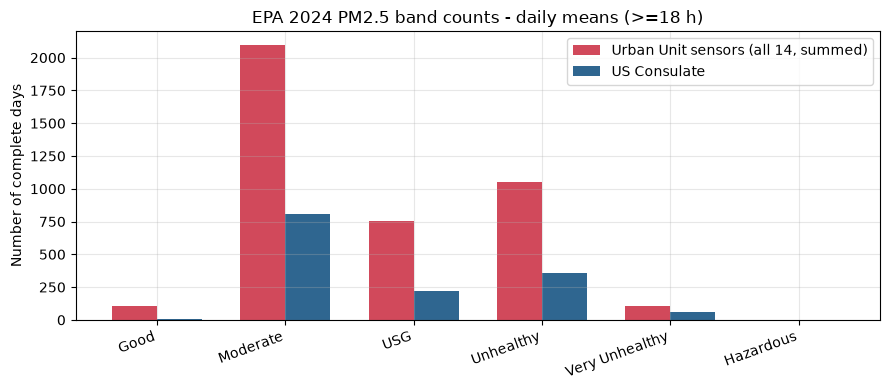

In [13]:
BAND_EDGES = [-np.inf, 9.0, 35.4, 55.4, 125.4, 225.4, np.inf]
BAND_LABELS = ["Good", "Moderate", "USG", "Unhealthy", "Very Unhealthy", "Hazardous"]


def band_counts(daily_df) -> pd.DataFrame:
    out = {}
    for col in daily_df.columns:
        s = daily_df[col].dropna()
        bands = pd.cut(s, bins=BAND_EDGES, labels=BAND_LABELS)
        out[col] = bands.value_counts().reindex(BAND_LABELS, fill_value=0)
    return pd.DataFrame(out)


sensor_bands = band_counts(sensor_daily)
sensor_bands["TOTAL"] = sensor_bands.sum(axis=1)
consulate_bands = (
    pd.cut(consulate_daily.dropna(), bins=BAND_EDGES, labels=BAND_LABELS)
    .value_counts()
    .reindex(BAND_LABELS, fill_value=0)
    .rename("US_CONSULATE")
)
display(sensor_bands)
display(consulate_bands)

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(BAND_LABELS))
width = 0.35
ax.bar(x - width / 2, sensor_bands["TOTAL"].values, width, label="Urban Unit sensors (all 14, summed)", color="#d1495b")
ax.bar(x + width / 2, consulate_bands.values, width, label="US Consulate", color="#2f6690")
ax.set_xticks(x)
ax.set_xticklabels(BAND_LABELS, rotation=20, ha="right")
ax.set_ylabel("Number of complete days")
ax.set_title("EPA 2024 PM2.5 band counts - daily means (>=18 h)")
ax.legend()
plt.tight_layout()
plt.show()


## 6. Sensor agreement

How closely do the 14 sensors move together day to day, and how well does
CAMS (the modelled pollution feed, D3) track their city-wide average? We
also check the spec's note that CAMS is "effectively one value for the whole
city" — i.e. nearly identical across all 14 site coordinates.


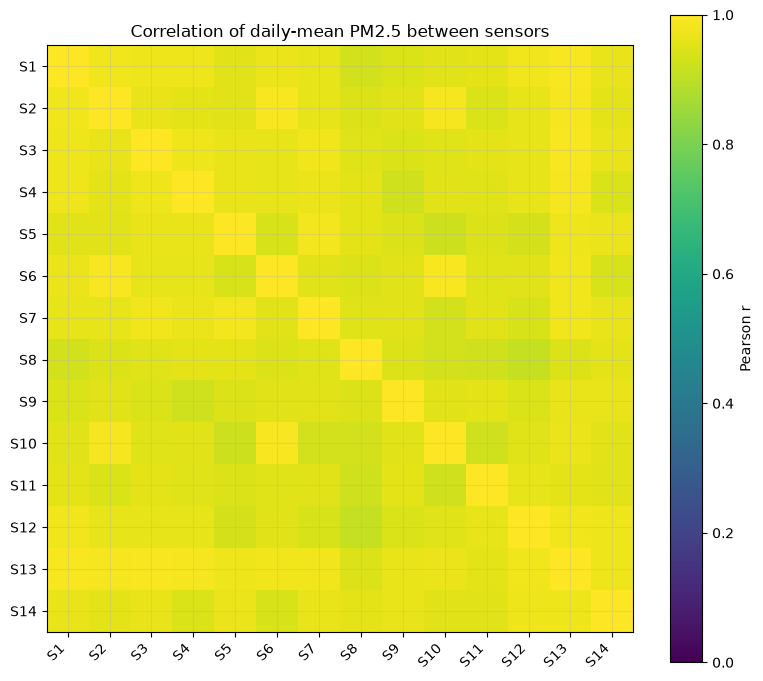

Pairwise sensor-sensor daily correlation: min=0.911  mean=0.959  max=0.992


In [14]:
corr = sensor_daily.corr()
order = sort_sensors(corr.columns)
corr = corr.loc[order, order]

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr.values, vmin=0, vmax=1, cmap="viridis")
ax.set_xticks(range(len(order)))
ax.set_xticklabels(order, rotation=45, ha="right")
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order)
ax.set_title("Correlation of daily-mean PM2.5 between sensors")
fig.colorbar(im, ax=ax, label="Pearson r")
plt.tight_layout()
plt.show()

off_diag = corr.values[~np.eye(len(corr), dtype=bool)]
print(f"Pairwise sensor-sensor daily correlation: min={off_diag.min():.3f}  mean={off_diag.mean():.3f}  max={off_diag.max():.3f}")


In [15]:
cams_wide = cams.dropna(subset=["time"]).pivot_table(index="time", columns="sensor_id", values="pm2_5")
cams_spread = cams_wide.max(axis=1) - cams_wide.min(axis=1)
print(f"CAMS pm2_5 spread across the 14 site coordinates per hour: mean={cams_spread.mean():.4f}  "
      f"max={cams_spread.max():.4f} µg/m³  (near zero => effectively one city-wide value)")

cams_city_daily = cams_wide.mean(axis=1).resample("D").mean()

cams_vs_sensors = pd.concat(
    [sensor_city_avg_daily.rename("sensor_avg"), cams_city_daily.rename("cams")], axis=1
).dropna()
r_cams = cams_vs_sensors["sensor_avg"].corr(cams_vs_sensors["cams"])
bias_cams = (cams_vs_sensors["cams"] - cams_vs_sensors["sensor_avg"]).mean()
print(f"CAMS vs sensor city-average daily PM2.5: n={len(cams_vs_sensors)} days, r={r_cams:.3f}, "
      f"mean bias (CAMS - sensors) = {bias_cams:+.1f} µg/m³")


CAMS pm2_5 spread across the 14 site coordinates per hour: mean=0.0000  max=0.0000 µg/m³  (near zero => effectively one city-wide value)
CAMS vs sensor city-average daily PM2.5: n=505 days, r=0.733, mean bias (CAMS - sensors) = -14.5 µg/m³


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_10416\2651602691.py:8: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  cams_vs_sensors = pd.concat(


## 7. Weather links

Correlation of the sensor city-average daily-mean PM2.5 with daily-mean
weather variables (averaged across the 14 sites, since ERA5 only resolves to
~4 distinct grid cells across them).


Correlation of city-average daily-mean PM2.5 with daily-mean weather variables:
temperature_2m          -0.652
wind_speed_10m          -0.627
relative_humidity_2m    -0.625
boundary_layer_height   -0.483
precipitation           -0.074


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_10416\3322645338.py:5: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  combo = pd.concat([sensor_city_avg_daily.rename("pm25"), weather_daily], axis=1).dropna(subset=["pm25"])


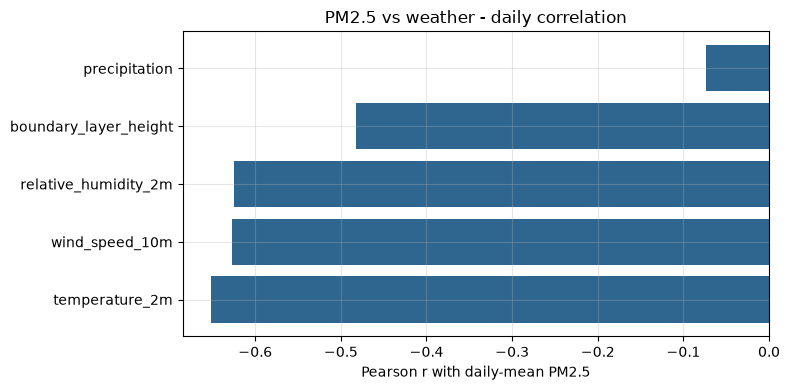

In [16]:
weather_vars = ["wind_speed_10m", "relative_humidity_2m", "temperature_2m", "boundary_layer_height", "precipitation"]
weather_daily = weather.dropna(subset=["time"]).groupby(weather["time"].dt.floor("D"))[weather_vars].mean()
weather_daily.index.name = "date"

combo = pd.concat([sensor_city_avg_daily.rename("pm25"), weather_daily], axis=1).dropna(subset=["pm25"])
weather_corr = combo.corr()["pm25"].drop("pm25").sort_values()
print("Correlation of city-average daily-mean PM2.5 with daily-mean weather variables:")
print(weather_corr.round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 4))
colors = ["#2f6690" if v < 0 else "#d1495b" for v in weather_corr.values]
ax.barh(weather_corr.index, weather_corr.values, color=colors)
ax.set_xlabel("Pearson r with daily-mean PM2.5")
ax.set_title("PM2.5 vs weather - daily correlation")
plt.tight_layout()
plt.show()


## 8. Raw vs corrected?

Low-cost optical PM2.5 sensors are known to read high in humid air (water on
the aerosol inflates the optical signal) unless already humidity-corrected.
We check that directly, then compare Consulate-vs-sensor PM2.5 levels by
calendar month — **with a caveat**: the two datasets never overlap in time
(Consulate: 2019-2025; sensors: 2025-2026), so any difference could be a
real multi-year trend, not just a sensor-vs-reference offset. Treat this
comparison as suggestive, not conclusive.


PM2.5 vs RH correlation: overall r=-0.265 (n=101,988)
  RH>80% subset:  r=0.105 (n=29,674), mean PM2.5=35.6 µg/m³
  RH<=80% subset: mean PM2.5=50.2 µg/m³


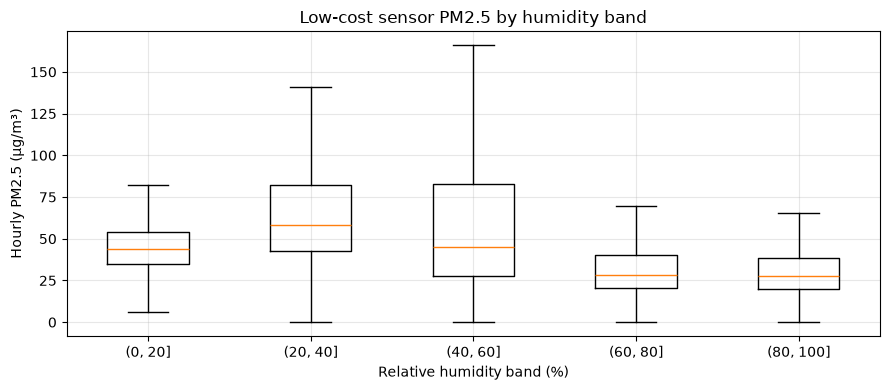

In [17]:
sw = pd.merge(
    sensors[["sensor_id", "time", "pm25"]],
    weather[["sensor_id", "time", "relative_humidity_2m"]],
    on=["sensor_id", "time"], how="inner",
).dropna()

high_rh = sw[sw["relative_humidity_2m"] > 80]
low_rh = sw[sw["relative_humidity_2m"] <= 80]
r_all = sw["pm25"].corr(sw["relative_humidity_2m"])
r_high = high_rh["pm25"].corr(high_rh["relative_humidity_2m"])
print(f"PM2.5 vs RH correlation: overall r={r_all:.3f} (n={len(sw):,})")
print(f"  RH>80% subset:  r={r_high:.3f} (n={len(high_rh):,}), mean PM2.5={high_rh['pm25'].mean():.1f} µg/m³")
print(f"  RH<=80% subset: mean PM2.5={low_rh['pm25'].mean():.1f} µg/m³")

rh_bins = [0, 20, 40, 60, 80, 100]
sw["rh_bin"] = pd.cut(sw["relative_humidity_2m"], bins=rh_bins)
groups = [sw.loc[sw["rh_bin"] == b, "pm25"].dropna().values for b in sw["rh_bin"].cat.categories]

fig, ax = plt.subplots(figsize=(9, 4))
ax.boxplot(groups, tick_labels=[str(b) for b in sw["rh_bin"].cat.categories], showfliers=False)
ax.set_xlabel("Relative humidity band (%)")
ax.set_ylabel("Hourly PM2.5 (µg/m³)")
ax.set_title("Low-cost sensor PM2.5 by humidity band")
plt.tight_layout()
plt.show()


In [18]:
consulate_monthly = consulate_daily.groupby(consulate_daily.index.month).mean()
sensor_monthly = sensor_city_avg_daily.groupby(sensor_city_avg_daily.index.month).mean()
compare = pd.DataFrame({
    "consulate_2019_2025_mean": consulate_monthly,
    "sensors_2025_2026_mean": sensor_monthly,
})
compare["diff_sensor_minus_consulate"] = compare["sensors_2025_2026_mean"] - compare["consulate_2019_2025_mean"]
compare.index.name = "month"
display(compare.round(1))


,consulate_2019_2025_mean,sensors_2025_2026_mean,diff_sensor_minus_consulate
month,,,
1,93.9,80.2,-13.8
2,68.8,64.9,-3.9
3,46.0,34.0,-12.0
4,29.9,30.9,1.0
5,25.5,25.2,-0.2
6,27.2,25.6,-1.6
7,27.2,24.5,-2.7
8,24.0,23.3,-0.7
9,28.5,28.1,-0.4


## 9. Findings

The cell below prints the headline numbers gathered above as a plain bullet
list, and writes the same findings (plus a compact coverage table) to
`docs/report/data_exploration.md` for the written report.


In [19]:
best_cov = sensor_coverage.loc[sensor_coverage["pct_complete"].idxmax()]
worst_cov = sensor_coverage.loc[sensor_coverage["pct_complete"].idxmin()]
worst_gap = sensor_coverage.loc[sensor_coverage["longest_gap_hours"].idxmax()]

good_total = int(sensor_bands.loc["Good", "TOTAL"])
hazardous_total = int(sensor_bands.loc["Hazardous", "TOTAL"])
moderate_total = int(sensor_bands.loc["Moderate", "TOTAL"])
sensor_days_total = int(sensor_bands["TOTAL"].sum())

findings = f'''\
## Findings

### Coverage
- {len(sensor_coverage)} sensors, {sensor_coverage['start'].min().date()} to {sensor_coverage['end'].max().date()}.
- {total_complete_sensor_days:,} complete sensor-days total (>=18 valid hours/day); mean completeness {sensor_coverage['pct_complete'].mean():.1f}% of all expected hours.
- Best coverage: {best_cov['sensor_id']} ({best_cov['pct_complete']}%). Worst: {worst_cov['sensor_id']} ({worst_cov['pct_complete']}%).
- Longest single gap: {worst_gap['sensor_id']}, {int(worst_gap['longest_gap_hours']):,} hours ({worst_gap['longest_gap_hours']/24:.1f} days).
- US Consulate: {consulate_coverage.iloc[0]['complete_days']:,} complete days, {consulate_coverage.iloc[0]['start'].date()} to {consulate_coverage.iloc[0]['end'].date()} (no overlap with the sensor period).

### Faults (measured, not yet cleaned)
- Negatives: {int(fault_totals['negatives'])} across all sensors.
- Zeros: {int(fault_totals['zeros'])}.
- Flat-line hours (>=6 h repeated value): {int(fault_totals['flat_line_hours'])}.
- Spikes (>500 ug/m3 or >5x rolling median): {int(fault_totals['spikes'])}.
- Hours with observed_count < expected_count: {int(fault_totals['observed_lt_expected'])}.

### Bands (daily means, >=18 h, EPA 2024 breakpoints)
- Sensor city total: Good {good_total}, Moderate {moderate_total}, USG {int(sensor_bands.loc['USG','TOTAL'])}, \
Unhealthy {int(sensor_bands.loc['Unhealthy','TOTAL'])}, Very Unhealthy {int(sensor_bands.loc['Very Unhealthy','TOTAL'])}, \
Hazardous {hazardous_total}, out of {sensor_days_total} sensor-days.
- Hazardous is {'empty' if hazardous_total == 0 else f'rare ({hazardous_total} days)'} -> merge with Very Unhealthy for classification (spec §6.4).
- Good is {'rare' if good_total < 30 else 'present'} ({good_total} sensor-days) -> check per-sensor training-split counts in Phase 2; merge with Moderate if <30 in the training split.
- US Consulate bands: {consulate_bands.to_dict()}.

### Sensor agreement
- Pairwise daily-mean correlation between sensors: min {off_diag.min():.3f}, mean {off_diag.mean():.3f}, max {off_diag.max():.3f}.
- CAMS spread across the 14 site coordinates: mean {cams_spread.mean():.4f} ug/m3, max {cams_spread.max():.4f} ug/m3 -> confirms CAMS is effectively one city-wide value, not site-specific.
- CAMS vs sensor city-average daily PM2.5: r={r_cams:.3f}, mean bias (CAMS - sensors) = {bias_cams:+.1f} ug/m3 over {len(cams_vs_sensors)} days.

### Weather links (daily-mean PM2.5 vs daily-mean weather)
{chr(10).join(f"- {k}: r={v:.3f}" for k, v in weather_corr.items())}

### Raw vs corrected
- PM2.5 vs relative humidity: overall r={r_all:.3f} (n={len(sw):,}); RH>80% subset r={r_high:.3f} (n={len(high_rh):,}).
- Mean PM2.5 at RH>80% = {high_rh['pm25'].mean():.1f} ug/m3 vs RH<=80% = {low_rh['pm25'].mean():.1f} ug/m3 -> {"higher PM2.5 at high RH, consistent with humidity-inflated (uncorrected) low-cost readings" if high_rh['pm25'].mean() > low_rh['pm25'].mean() else "PM2.5 is actually LOWER at high RH; no sign of humidity inflation in the raw signal, but likely confounded by season (humid spells coincide with monsoon rain, which washes out PM2.5) rather than proof the sensors are already corrected"}.
- Consulate (2019-2025) vs sensors (2025-2026), same calendar months: sensors read \
{'higher' if compare['diff_sensor_minus_consulate'].mean() > 0 else 'lower'} on average by {compare['diff_sensor_minus_consulate'].mean():.1f} ug/m3. \
Caveat: periods do not overlap, so this mixes any real year-to-year trend with sensor-vs-reference offset; treat as suggestive only.

### Recommended Phase 2 decisions
- Fault rules: drop negatives and spikes (>500 ug/m3 or >5x the 25 h rolling median) before imputing; treat flat-line runs >=24 h as missing; keep zeros and under-reported hours (down-weighted) as real.
- Gap handling: interpolate gaps up to a few hours; drop (and log) windows longer than the longest-gap threshold found above rather than filling them.
- Sensors to keep: all 14 (each already clears the >=150-day / >=18h-per-day bar used in spec §5.2); revisit {worst_cov['sensor_id']} if its {worst_cov['pct_complete']}% completeness causes problems once lag features are built.
- Band merges: merge Hazardous into Very Unhealthy everywhere (0-{hazardous_total} days); re-check Good vs Moderate merge once the training split is fixed (<30 samples rule, spec §6.4).
- Train/val/test split (time-ordered, whole seasons kept together): train on the first full annual cycle, validate on the following full season, test on the most recent season, e.g. train {sensor_coverage['start'].min().date()}-2026-05-31, validation 2026-06-01-2026-08-31, test 2026-09-01-{sensor_coverage['end'].max().date()} (covers monsoon in validation and the start of winter smog season in test) - confirm exact cut-offs once Phase 2 feature lags are built (lags need lead-in data just before each split boundary).
'''

print(findings)


## Findings

### Coverage
- 14 sensors, 2025-06-19 to 2026-11-08.
- 4,113 complete sensor-days total (>=18 valid hours/day); mean completeness 66.4% of all expected hours.
- Best coverage: S1 (85.6%). Worst: S14 (32.5%).
- Longest single gap: S13, 5,533 hours (230.5 days).
- US Consulate: 1,454 complete days, 2019-05-23 to 2025-03-04 (no overlap with the sensor period).

### Faults (measured, not yet cleaned)
- Negatives: 0 across all sensors.
- Zeros: 5.
- Flat-line hours (>=6 h repeated value): 0.
- Spikes (>500 ug/m3 or >5x rolling median): 79.
- Hours with observed_count < expected_count: 0.

### Bands (daily means, >=18 h, EPA 2024 breakpoints)
- Sensor city total: Good 107, Moderate 2096, USG 758, Unhealthy 1049, Very Unhealthy 103, Hazardous 0, out of 4113 sensor-days.
- Hazardous is empty -> merge with Very Unhealthy for classification (spec §6.4).
- Good is present (107 sensor-days) -> check per-sensor training-split counts in Phase 2; merge with Moderate if <30 in the trainin

In [20]:
coverage_md_rows = "\n".join(
    f"| {r.sensor_id} | {r.start.date()} | {r.end.date()} | {r.pct_complete}% | {r.complete_days} | {r.longest_gap_hours} |"
    for r in sensor_coverage.itertuples()
)
coverage_md_rows += (
    f"\n| US_CONSULATE | {consulate_coverage.iloc[0]['start'].date()} | {consulate_coverage.iloc[0]['end'].date()} | "
    f"{consulate_coverage.iloc[0]['pct_complete']}% | {consulate_coverage.iloc[0]['complete_days']} | "
    f"{consulate_coverage.iloc[0]['longest_gap_hours']} |"
)

report = f'''# Data exploration - Phase 1 findings

Generated from `notebooks/01_explore_data.ipynb`. See that notebook for the full analysis, figures and code.

## Coverage table

| Sensor | First reading | Last reading | % complete | Complete days (>=18h) | Longest gap (h) |
|---|---|---|---|---|---|
{coverage_md_rows}

{findings}
'''

REPORT_PATH.parent.mkdir(parents=True, exist_ok=True)
REPORT_PATH.write_text(report, encoding="utf-8")
display(Markdown(f"Findings written to `{REPORT_PATH.relative_to(ROOT)}`"))


Findings written to `docs\report\data_exploration.md`